# Latent-action model (LAM), T1

Name the motion between two frames with a few numbers, from video alone. Script version: `experiments/lam/scripts/lam.py` (results in `experiments/lam/notes.md`).


In [1]:
%load_ext autoreload
%autoreload 2
from notebook_cache import NotebookCache

cache = NotebookCache('../cache/lam_nb')

## Step 0: data

Joints, demo ids, top-camera frames (decoded once by the script, `cache/lam/`).


In [2]:
import numpy as np
from frozendict import frozendict
from uwm_parts import load_table

NAME = 'pick_place_cube_n100'
state, action, episode = load_table(NAME)
top = np.load(f'../cache/lam/{NAME}_top.npy')  # [N, 3, 128, 128] uint8
print(f'{top.shape=}  {state.shape=}  demos {episode.max() + 1}')

top.shape=(21295, 3, 128, 128)  state.shape=(21295, 8)  demos 100


## Step 1: what changes in 8 steps

Three moments of one demo: frame t, frame t+8, and where they differ.


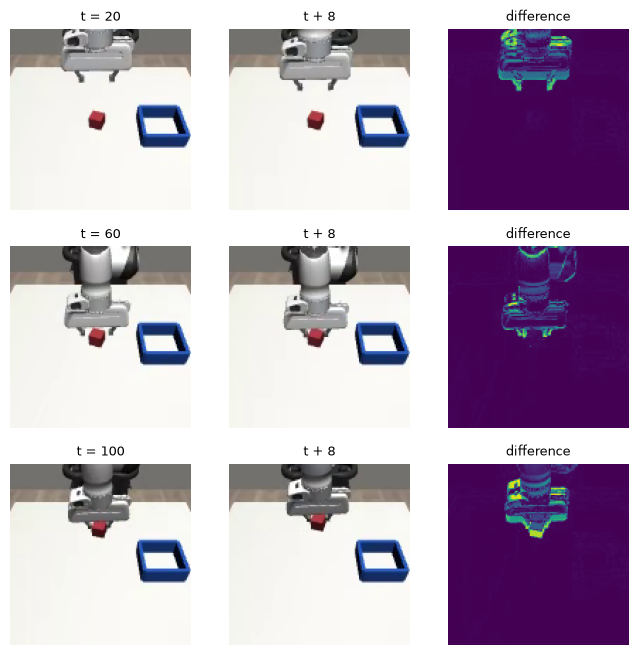

In [3]:
import matplotlib.pyplot as plt

GAP = 8
start = np.flatnonzero(episode == 31)[0]
fig, axs = plt.subplots(3, 3, figsize=(8, 8))
for row, step in enumerate([20, 60, 100]):
    f0, f1 = top[start + step], top[start + step + GAP]
    diff = np.abs(f1.astype(int) - f0.astype(int)).sum(0)  # [128, 128]
    for ax, im, name in zip(
        axs[row],
        [f0.transpose(1, 2, 0), f1.transpose(1, 2, 0), diff],
        [f't = {step}', f't + {GAP}', 'difference'],
    ):
        ax.imshow(im)
        ax.set_title(name, fontsize=9)
        ax.axis('off')
plt.show()

In [4]:
ok = np.flatnonzero(episode[:-GAP] == episode[GAP:])  # rows t with t + 8 in the same demo
d = np.abs(top[ok[::50] + GAP].astype(int) - top[ok[::50]].astype(int)).sum(1)  # [n, 128, 128]
print(f'{len(d)} pairs: {(d > 30).mean():.1%} of pixels change in 8 steps')

410 pairs: 10.2% of pixels change in 8 steps


## Step 2: the encoder

(frame t, frame t+8) stacked as 6 channels -> 3 stride-2 convs -> average over the map -> z (8 numbers).


In [5]:
import torch
from torch import nn

dev = 'cuda'
Z = 8  # numbers in a motion note


def down(i, o):
    # halves height and width
    return nn.Sequential(nn.Conv2d(i, o, 4, stride=2, padding=1), nn.GroupNorm(8, o), nn.SiLU())


torch.manual_seed(0)
enc = nn.ModuleDict(
    dict(
        convs=nn.Sequential(
            down(6, 32), down(32, 64), down(64, 128), nn.Conv2d(128, 128, 3, padding=1)
        ),
        out=nn.Linear(128, Z),  # after averaging over the map
    )
).to(dev)

In [6]:
x = torch.tensor(np.concatenate([top[ok[:3]], top[ok[:3] + GAP]], 1), device=dev) / 255
with torch.no_grad():
    h = enc['convs'](x)
    z = enc['out'](h.mean((2, 3)))
print(f'{x.shape=}  {h.shape=}  {z.shape=}')

x.shape=torch.Size([3, 6, 128, 128])  h.shape=torch.Size([3, 128, 16, 16])  z.shape=torch.Size([3, 8])


## Step 3: the decoder

(frame t, z) -> frame t+8. Frame t becomes a 16x16 map; z scales and shifts every cell of it (FiLM); 3 up-convs draw the change, added to frame t.


In [7]:
def up(i, o):
    # doubles height and width
    return nn.Sequential(
        nn.ConvTranspose2d(i, o, 4, stride=2, padding=1), nn.GroupNorm(8, o), nn.SiLU()
    )


dec = nn.ModuleDict(
    dict(
        convs=nn.Sequential(
            down(3, 32), down(32, 64), down(64, 128), nn.Conv2d(128, 128, 3, padding=1)
        ),
        film=nn.Linear(Z, 2 * 128),  # z -> a scale and a shift per feature
        up=nn.Sequential(
            up(128, 64), up(64, 32), nn.ConvTranspose2d(32, 3, 4, stride=2, padding=1)
        ),
    )
).to(dev)
print(f'{sum(p.numel() for m in (enc, dec) for p in m.parameters()) / 1e6:.2f}M params')

0.80M params


In [8]:
f0 = x[:, :3]  # frame t of the 3 pairs
with torch.no_grad():
    scale, shift = dec['film'](z)[..., None, None].chunk(2, 1)  # [3, 128, 1, 1] each
    g = dec['convs'](f0) * (1 + scale) + shift  # [3, 128, 16, 16]
    f1_hat = f0 + dec['up'](g)
print(f'{g.shape=}  {f1_hat.shape=}')

g.shape=torch.Size([3, 128, 16, 16])  f1_hat.shape=torch.Size([3, 3, 128, 128])


## Step 4: the loss

Redraw frame t+8; squared pixel error, against copying frame t ("nothing moved").


In [9]:
val = np.random.default_rng(0).permutation(100)[:10]  # the dreamzero split's held-out demos
rows = frozendict(train=ok[~np.isin(episode[ok], val)], val=ok[np.isin(episode[ok], val)])
print({k: len(v) for k, v in rows.items()})
tasks = {NAME: frozendict(top=top, rows=rows)}  # step 8 adds T2

{'train': 18436, 'val': 2059}


In [10]:
def frames(r):
    # rows -> [B, 3, 128, 128] float in [0, 1] on the GPU
    return torch.tensor(top[r], device=dev) / 255


def note(f0, f1):
    # the encoder: a pair of frames -> z [B, Z]
    return enc['out'](enc['convs'](torch.cat([f0, f1], 1)).mean((2, 3)))


def redraw(f0, z):
    # the decoder: frame t + z -> guess of frame t+8 [B, 3, 128, 128]
    scale, shift = dec['film'](z)[..., None, None].chunk(2, 1)
    return f0 + dec['up'](dec['convs'](f0) * (1 + scale) + shift)

In [11]:
r = np.random.default_rng(0).choice(rows['train'], 64)
f0, f1 = frames(r), frames(r + GAP)
with torch.no_grad():
    err = (redraw(f0, note(f0, f1)) - f1).square().mean()
print(f'untrained: draw {err:.4f}   copy frame t {(f0 - f1).square().mean():.4f}')

untrained: draw 0.3521   copy frame t 0.0126


## Step 5: pack into a class

Steps 2-4's pieces as one `LAM` module; same weights must give the same z and guess.


In [12]:
class LAM(nn.Module):
    # step 2's encoder + step 3's decoder; note and redraw as in step 4
    def __init__(self):
        super().__init__()
        self.enc_convs = nn.Sequential(
            down(6, 32), down(32, 64), down(64, 128), nn.Conv2d(128, 128, 3, padding=1)
        )
        self.enc_out = nn.Linear(128, Z)
        self.dec_convs = nn.Sequential(
            down(3, 32), down(32, 64), down(64, 128), nn.Conv2d(128, 128, 3, padding=1)
        )
        self.film = nn.Linear(Z, 2 * 128)
        self.up = nn.Sequential(
            up(128, 64), up(64, 32), nn.ConvTranspose2d(32, 3, 4, stride=2, padding=1)
        )

    def note(self, f0, f1):
        return self.enc_out(self.enc_convs(torch.cat([f0, f1], 1)).mean((2, 3)))

    def redraw(self, f0, z):
        scale, shift = self.film(z)[..., None, None].chunk(2, 1)
        return f0 + self.up(self.dec_convs(f0) * (1 + scale) + shift)

In [13]:
net = LAM().to(dev)
loose = [enc['convs'], enc['out'], dec['convs'], dec['film'], dec['up']]
for m, piece in zip([net.enc_convs, net.enc_out, net.dec_convs, net.film, net.up], loose):
    m.load_state_dict(piece.state_dict())
with torch.no_grad():
    z = net.note(f0, f1)
    diff = [
        (z - note(f0, f1)).abs().max().item(),
        (net.redraw(f0, z) - redraw(f0, z)).abs().max().item(),
    ]
print(f'max diff vs loose pieces (z, guess): {diff}')

max diff vs loose pieces (z, guess): [0.0, 4.76837158203125e-07]


## Step 6: train on forward pairs

Every 1000 steps, on 512 val pairs, the drawing error / copy's with: the right z, the average z (a blank note), another pair's z (a wrong note). If z is used, right < average < wrong.


In [31]:
@cache
def train_lam(
    reverse: bool,
    steps: int = 10000,
    B: int = 64,
    lr: float = 1e-3,
    seed: int = 0,
    task: str = NAME,
):
    # a fresh LAM; reverse: half the pairs played backwards;
    # out: weights (CPU), log rows [step, train loss, val right z, avg z, wrong z] (all / copy)
    img, task_rows = tasks[task]['top'], tasks[task]['rows']

    def fr(r):
        return torch.tensor(img[r], device=dev) / 255

    torch.manual_seed(seed)
    rng = np.random.default_rng(seed)
    net = LAM().to(dev)
    opt = torch.optim.AdamW(net.parameters(), lr=lr)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, steps, eta_min=lr / 100)
    vr = np.random.default_rng(1).choice(task_rows['val'], 512, replace=False)
    v0, v1 = fr(vr), fr(vr + GAP)
    copy_err = (v0 - v1).square().mean()
    log = []
    for step in range(1, steps + 1):
        r0 = rng.choice(task_rows['train'], B)
        r1 = r0 + GAP
        if reverse:
            back = rng.random(B) < 0.5
            r0, r1 = np.where(back, r1, r0), np.where(back, r0, r1)
        f0, f1 = fr(r0), fr(r1)
        with torch.autocast('cuda', dtype=torch.bfloat16):
            loss = (net.redraw(f0, net.note(f0, f1)).float() - f1).square().mean()
        opt.zero_grad()
        loss.backward()
        torch.nn.utils.clip_grad_norm_(net.parameters(), 1.0)
        opt.step()
        sched.step()
        if step % 1000 == 0:
            with torch.no_grad():
                z = net.note(v0, v1)
                err = [
                    (net.redraw(v0, x) - v1).square().mean() / copy_err
                    for x in (z, z.mean(0).expand_as(z), z.roll(1, 0))
                ]
            log.append([step, loss.item(), *[e.item() for e in err]])
            print(
                f'{step:5d}  train {loss:.5f}   val / copy: right z {err[0]:.3f}  '
                f'average z {err[1]:.3f}  wrong z {err[2]:.3f}'
            )
    return frozendict(weights={k: v.cpu() for k, v in net.state_dict().items()}, log=np.array(log))

train_lam: cached, 3 call(s) stored


In [32]:
run_fwd = train_lam(reverse=False)

 1000  train 0.00527   val / copy: right z 0.442  average z 0.442  wrong z 0.442
 2000  train 0.00324   val / copy: right z 0.297  average z 0.297  wrong z 0.297
 3000  train 0.00289   val / copy: right z 0.256  average z 0.256  wrong z 0.256
 4000  train 0.00242   val / copy: right z 0.230  average z 0.230  wrong z 0.230
 5000  train 0.00225   val / copy: right z 0.212  average z 0.212  wrong z 0.212
 6000  train 0.00242   val / copy: right z 0.202  average z 0.202  wrong z 0.202
 7000  train 0.00187   val / copy: right z 0.193  average z 0.193  wrong z 0.193
 8000  train 0.00199   val / copy: right z 0.187  average z 0.187  wrong z 0.187
 9000  train 0.00203   val / copy: right z 0.185  average z 0.185  wrong z 0.185
10000  train 0.00172   val / copy: right z 0.184  average z 0.184  wrong z 0.184


In [33]:
run_rev = train_lam(reverse=True)

 1000  train 0.00782   val / copy: right z 0.645  average z 0.645  wrong z 0.645
 2000  train 0.00657   val / copy: right z 0.573  average z 0.573  wrong z 0.573
 3000  train 0.00615   val / copy: right z 0.551  average z 0.551  wrong z 0.551
 4000  train 0.00582   val / copy: right z 0.506  average z 0.506  wrong z 0.506
 5000  train 0.00574   val / copy: right z 0.492  average z 0.492  wrong z 0.492
 6000  train 0.00597   val / copy: right z 0.494  average z 0.494  wrong z 0.494
 7000  train 0.00537   val / copy: right z 0.497  average z 0.497  wrong z 0.497
 8000  train 0.00291   val / copy: right z 0.257  average z 0.497  wrong z 0.720
 9000  train 0.00278   val / copy: right z 0.228  average z 0.481  wrong z 0.740
10000  train 0.00241   val / copy: right z 0.221  average z 0.479  wrong z 0.751


## Step 7: probes

Is the motion in z? Freeze the LAM, fit a small model z -> the real joint change state[t+8] − state[t] on train demos, score R² on val demos. The LAM never saw joints.
Control: the same probe on an untrained LAM (random convs already carry some signal).


In [27]:
probe_net = LAM().to(dev).eval()


def notes(weights, r, task=NAME, back=False):
    # rows -> z [n, 8] (numpy) from a LAM with these weights; back: the pair played backwards
    img = tasks[task]['top']
    probe_net.load_state_dict(weights)
    with torch.no_grad():
        zs = [
            probe_net.note(
                *(
                    torch.tensor(img[x], device=dev) / 255
                    for x in ((b + GAP, b) if back else (b, b + GAP))
                )
            )
            for b in np.array_split(r, len(r) // 256)
        ]
    return torch.cat(zs).cpu().numpy()

In [ ]:
torch.manual_seed(0)
untrained = {k: v.cpu() for k, v in LAM().state_dict().items()}
z = {
    name: {s: notes(w, rows[s]) for s in rows}
    for name, w in [('trained', run_rev['weights']), ('untrained', untrained)]
}
dx = {s: state[rows[s] + GAP] - state[rows[s]] for s in rows}  # the real joint change
print(z['trained']['train'].shape, dx['val'].shape)

(18436, 8) (2059, 8)


In [ ]:
"""
ridge: the W minimising  |XW − Y|² + λ|W|²
  gradient = 0:  2Xᵀ(XW − Y) + 2λW = 0
                 (XᵀX + λI) W     = XᵀY
                 W                = (XᵀX + λI)⁻¹ XᵀY
R² per output dim = 1 − Σ(y − ŷ)² / Σ(y − ȳ)²   (1 = perfect, 0 = always guessing the mean)
"""


def ridge_r2(x_tr, y_tr, x_va, y_va, lam=1e-3):
    # fit on train, R² per output dim on val; a column of ones is the bias
    a, b = np.c_[x_tr, np.ones(len(x_tr))], np.c_[x_va, np.ones(len(x_va))]
    w = np.linalg.solve(a.T @ a + lam * np.eye(a.shape[1]), a.T @ y_tr)
    return 1 - ((b @ w - y_va) ** 2).sum(0) / ((y_va - y_va.mean(0)) ** 2).sum(0)

In [ ]:
for name in z:
    r2 = ridge_r2(z[name]['train'], dx['train'], z[name]['val'], dx['val'])
    print(f'{name:9s} straight line: arm {r2[:7].mean():.2f}  gripper {r2[7]:.2f}')

trained   straight line: arm 0.69  gripper 0.20
untrained straight line: arm 0.27  gripper 0.19


In [ ]:
def knn_r2(x_tr, y_tr, x_va, y_va, k=20):
    # predict each val row as the average answer of its k nearest train z's; R² per dim
    m, s = x_tr.mean(0), x_tr.std(0) + 1e-6
    d = torch.cdist(torch.tensor((x_va - m) / s), torch.tensor((x_tr - m) / s))
    pred = y_tr[d.topk(k, largest=False).indices.numpy()].mean(1)
    return 1 - ((pred - y_va) ** 2).sum(0) / ((y_va - y_va.mean(0)) ** 2).sum(0)

In [ ]:
for name in z:
    r2 = knn_r2(z[name]['train'], dx['train'], z[name]['val'], dx['val'])
    print(f'{name:9s} 20 neighbours: arm {r2[:7].mean():.2f}  gripper {r2[7]:.2f}')

trained   20 neighbours: arm 0.89  gripper 0.86
untrained 20 neighbours: arm 0.66  gripper 0.61


### Fit on the 3 labelled demos

The policy only gets actions for 3 demos: does z still read well from ~600 rows instead of ~18k?


In [ ]:
train_demos = np.setdiff1d(np.arange(100), val)
three = np.random.default_rng(1).choice(train_demos, 10, replace=False)[:3]  # as the scripts
in3 = np.isin(episode[rows['train']], three)
print(three, in3.sum(), 'rows')

[31 42 77] 606 rows


In [ ]:
for name in z:
    zt, zv = z[name]['train'][in3], z[name]['val']
    lin = ridge_r2(zt, dx['train'][in3], zv, dx['val'])
    near = knn_r2(zt, dx['train'][in3], zv, dx['val'])
    print(
        f'{name:9s} line: arm {lin[:7].mean():.2f} gripper {lin[7]:.2f}   '
        f'neighbours: arm {near[:7].mean():.2f} gripper {near[7]:.2f}'
    )

trained   line: arm 0.68 gripper 0.21   neighbours: arm 0.80 gripper 0.61
untrained line: arm 0.27 gripper 0.20   neighbours: arm 0.50 gripper 0.36


### Change or position?

z should hold the move, not where the arm is. Same probes, three answers: the change, the joints after (t+8), the joints before (t).


In [ ]:
answers = {
    'change': dx,
    'after': {s: state[rows[s] + GAP] for s in rows},
    'before': {s: state[rows[s]] for s in rows},
}

In [ ]:
for name in z:
    for what, y in answers.items():
        r2 = knn_r2(z[name]['train'], y['train'], z[name]['val'], y['val'])
        print(f'{name:9s} {what:6s}  neighbours: arm {r2[:7].mean():.2f}  gripper {r2[7]:.2f}')

trained   change  neighbours: arm 0.89  gripper 0.86
trained   after   neighbours: arm 0.78  gripper 0.91
trained   before  neighbours: arm 0.78  gripper 0.89
untrained change  neighbours: arm 0.66  gripper 0.61
untrained after   neighbours: arm 0.67  gripper 0.61
untrained before  neighbours: arm 0.67  gripper 0.60


In [ ]:
# reference: how much position does the TRUE change alone give?
for what, y in answers.items():
    r2 = knn_r2(dx['train'], y['train'], dx['val'], y['val'])
    print(f'true change -> {what:6s}  neighbours: arm {r2[:7].mean():.2f}  gripper {r2[7]:.2f}')

true change -> change  neighbours: arm 0.99  gripper 1.00
true change -> after   neighbours: arm 0.85  gripper 0.92
true change -> before  neighbours: arm 0.85  gripper 0.92


## Step 8: T2-fixed, the same move in two places

Cube from one start into the left or the right bin. Carrying, the move itself is left or right;
lowering into the bin and releasing, the same move happens over either bin. A move-only z
should know the side while carrying and be at chance (50%) while lowering.


In [16]:
import sys

sys.path.insert(0, '../experiments/lam/scripts')
from lam import load

T2 = 'pick_place_two_bins_fixed_noise0025_n100'
state2, episode2, top2 = load(T2)  # decodes the top camera once (a few min), then cached
print(f'{top2.shape=}  {state2.shape=}')

top2.shape=(21741, 3, 128, 128)  state2.shape=(21741, 8)


In [17]:
ok2 = np.flatnonzero(episode2[:-GAP] == episode2[GAP:])
rows2 = frozendict(train=ok2[~np.isin(episode2[ok2], val)], val=ok2[np.isin(episode2[ok2], val)])
tasks[T2] = frozendict(top=top2, rows=rows2)
last2 = np.searchsorted(episode2, np.arange(100), side='right') - 1
side = np.sign(state2[last2, 0])  # per demo: base joint at the end, +1 / -1 = the two bins
print({k: len(v) for k, v in rows2.items()}, np.unique(side, return_counts=True))

{'train': 18810, 'val': 2131} (array([-1.,  1.], dtype=float32), array([50, 50]))


In [18]:
run_t2 = train_lam(reverse=True, task=T2)

 1000  train 0.00815   val / copy: right z 0.695  average z 0.695  wrong z 0.695
 2000  train 0.00701   val / copy: right z 0.610  average z 0.610  wrong z 0.610
 3000  train 0.00641   val / copy: right z 0.576  average z 0.576  wrong z 0.576
 4000  train 0.00586   val / copy: right z 0.556  average z 0.556  wrong z 0.556
 5000  train 0.00632   val / copy: right z 0.548  average z 0.548  wrong z 0.548
 6000  train 0.00635   val / copy: right z 0.545  average z 0.545  wrong z 0.545
 7000  train 0.00424   val / copy: right z 0.430  average z 0.579  wrong z 0.701
 8000  train 0.00348   val / copy: right z 0.331  average z 0.586  wrong z 0.780
 9000  train 0.00322   val / copy: right z 0.317  average z 0.592  wrong z 0.786
10000  train 0.00301   val / copy: right z 0.311  average z 0.592  wrong z 0.786


### Which bin? z vs the true move vs the position, by phase

Each val row: predict the demo's bin from its 20 nearest train rows, scored per fifth of the demo.


In [21]:
z2 = {s: notes(run_t2['weights'], rows2[s], T2) for s in rows2}
first2 = np.searchsorted(episode2, np.arange(100))
lens2 = np.bincount(episode2)
phase = {s: (5 * (r - first2[episode2[r]]) // lens2[episode2[r]]) for s, r in rows2.items()}
bin_of = {s: side[episode2[r]] for s, r in rows2.items()}
inputs = {
    'z': z2,
    'true move': {s: state2[r + GAP] - state2[r] for s, r in rows2.items()},
    'position': {s: state2[r] for s, r in rows2.items()},
}

In [22]:
def knn_side(x_tr, y_tr, x_va, y_va, k=20):
    # each val row: majority bin of its k nearest train rows; right (1) or wrong (0) per row
    m, s = x_tr.mean(0), x_tr.std(0) + 1e-6
    d = torch.cdist(torch.tensor((x_va - m) / s), torch.tensor((x_tr - m) / s))
    vote = y_tr[d.topk(k, largest=False).indices.numpy()].mean(1)
    return np.sign(vote) == y_va

In [23]:
for what, x in inputs.items():
    right = knn_side(x['train'], bin_of['train'], x['val'], bin_of['val'])
    per_phase = [f'{right[phase["val"] == p].mean():.0%}' for p in range(5)]
    print(f'{what:10s} bin right, by fifth of the demo: {"  ".join(per_phase)}')

z          bin right, by fifth of the demo: 30%  28%  32%  53%  83%
true move  bin right, by fifth of the demo: 32%  32%  40%  88%  58%
position   bin right, by fifth of the demo: 50%  66%  48%  84%  100%


### All 100 demos, 5 folds

10 val demos = 10 votes per fifth (about ±15%). Hold out 20 demos at a time, 5 times, so every
demo is scored once (the LAM saw 90 of them in training; the probe never sees the held-out 20).

In [24]:
e_all = episode2[ok2]
y_all = side[e_all]
phase_all = 5 * (ok2 - first2[e_all]) // lens2[e_all]
inputs_all = {
    'z': notes(run_t2['weights'], ok2, T2),
    'true move': state2[ok2 + GAP] - state2[ok2],
    'position': state2[ok2],
}

In [25]:
def by_fold(x, folds=5):
    # each demo held out once; right/wrong per row from the other folds' 20 nearest rows
    group = (np.random.default_rng(0).permutation(100) % folds)[e_all]
    right = np.zeros(len(x), bool)
    for f in range(folds):
        out = group == f
        right[out] = knn_side(x[~out], y_all[~out], x[out], y_all[out])
    return right

In [26]:
for what, x in inputs_all.items():
    right = by_fold(x)
    per_phase = [f'{right[phase_all == p].mean():.0%}' for p in range(5)]
    print(f'{what:10s} bin right, by fifth of the demo: {"  ".join(per_phase)}')

z          bin right, by fifth of the demo: 42%  42%  41%  61%  82%
true move  bin right, by fifth of the demo: 42%  43%  45%  93%  69%
position   bin right, by fifth of the demo: 53%  52%  52%  81%  100%


### Direction, or away/toward the center?

Rows where the base turns most (the carry). z of each pair forward and played backwards, per bin.
If z = direction: forward-A sits near backward-B (both turn the same way).
If z = away/toward the center: forward-A sits near forward-B (both swing outward).

In [28]:
turn = state2[ok2 + GAP, 0] - state2[ok2, 0]  # base joint change over 8 steps
swing = ok2[np.abs(turn) > np.quantile(np.abs(turn), 0.9)]  # the 10% biggest turns
groups = {}
for b in [-1, 1]:
    r = swing[side[episode2[swing]] == b]
    for back in [False, True]:
        name = f'{"back" if back else "fwd"} {"A" if b < 0 else "B"}'
        groups[name] = notes(run_t2['weights'], r, T2, back)
print({k: len(v) for k, v in groups.items()})

{'fwd A': 1061, 'back A': 1061, 'fwd B': 1033, 'back B': 1033}


In [29]:
scale = inputs_all['z'].std(0)  # z in std units
mid = {k: v.mean(0) / scale for k, v in groups.items()}
print(' ' * 7 + ''.join(f'{k:>8s}' for k in mid))
for k, m in mid.items():
    print(f'{k:7s}' + ''.join(f'{np.linalg.norm(m - o):8.2f}' for o in mid.values()))

          fwd A  back A   fwd B  back B
fwd A      0.00    1.80    0.18    1.81
back A     1.80    0.00    1.88    0.38
fwd B      0.18    1.88    0.00    1.87
back B     1.81    0.38    1.87    0.00


### What does release look like at each bin?

One demo per bin, at 85% of the way through: frame t, frame t+8, and where they differ.

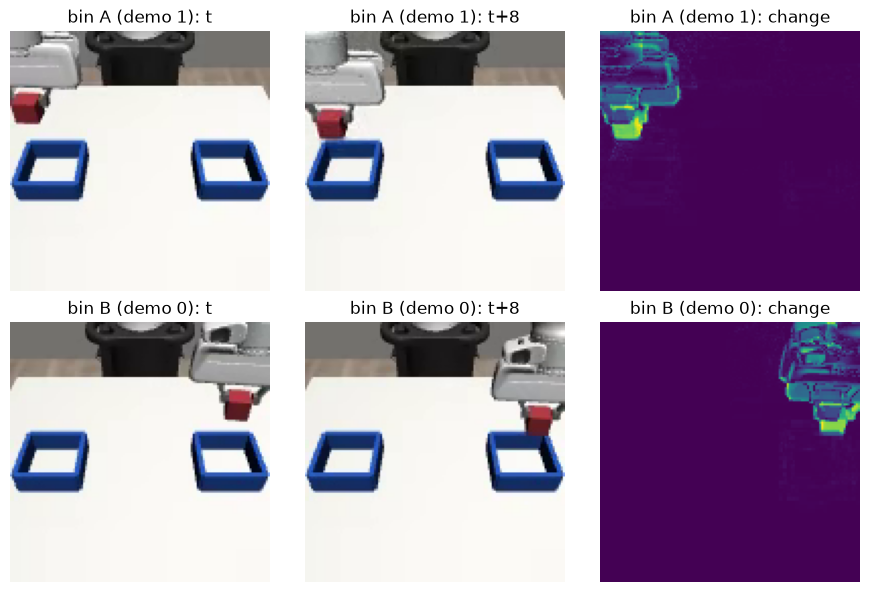

In [30]:
fig, axs = plt.subplots(2, 3, figsize=(9, 6))
for row, b in zip(axs, [-1, 1]):
    e = np.flatnonzero(side == b)[0]
    r = first2[e] + int(0.85 * lens2[e])
    pair = [top2[r].transpose(1, 2, 0), top2[r + GAP].transpose(1, 2, 0)]
    diff = np.abs(pair[1].astype(int) - pair[0].astype(int)).sum(2)
    for ax, img, title in zip(row, [*pair, diff], ['t', 't+8', 'change']):
        ax.imshow(img)
        ax.set_title(f'bin {"A" if b < 0 else "B"} (demo {e}): {title}')
        ax.axis('off')
plt.tight_layout()